# Insufficient trough passage: were WY2026's inter-episode gaps short because the troughs were weak, not just brief?

**Motivation.** A specific refinement of the season-clustering finding: *"the repeated
development of ridges, combined with insufficient intervening trough passages, may
have been more important for overall persistence than the intensity of any individual
ridge."* Two of its three claims are already established by prior notebooks --
repeated ridge development is real and record-breaking
(`CA_ridging_persistence_season_clustering.ipynb`: WY2026 is the 100th-percentile
season on episode count and total coverage), and individual-episode intensity does not
predict duration (`CA_ridging_persistence_drivers.ipynb`: peak/mean intensity null).
The third claim -- *insufficient trough passage* -- has not actually been tested.
`CA_ridging_persistence_season_clustering.ipynb` only measured gap **length** (calendar
days between episodes, found to be unusually short); it never checked gap **depth** --
whether the circulation actually reached trough conditions during those gaps, or
merely relaxed toward normal without ever going negative. A short gap with a genuine
deep trough is a different physical situation from a short gap where the ridge barely
let up at all.

**Two gap-depth metrics, computed from the standardized Z500/T700 anomaly series
already built throughout this project (no new fetch):**
- `gap_min_sanom`: the minimum (most negative) standardized anomaly reached anywhere
  within an inter-episode gap -- how deep the trough got, continuous, not thresholded.
- `gap_frac_below_neg1`: fraction of the gap's own days with anomaly <= -1 sigma -- the
  same symmetric threshold used to *detect* a ridging episode in the first place,
  applied to the trough side, so "did a trough-strength anomaly occur at all" is
  answered on the same terms the ridge detector itself uses.

**Two tests:** (1) **event-level** -- does a shallower gap immediately preceding an
episode (weak/no trough) predict that episode's own duration, across the full
1990-2025 record; (2) **season-level** -- does a season's weakest trough-reset across
all its gaps predict how much total time that season spent under ridging. Then: where
do WY2026's three actual gaps sit in both distributions.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, percentileofscore
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
YEAR_2026 = 2026
THRESHOLD_SD = 1
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)

CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1
TROUGH_THRESH = -1.0   # symmetric to the +1 sigma ridge-detection threshold


## 1. Build the full continuous standardized-anomaly series, 1990-2026, both variables

Same detrended calendar-day standardization as every notebook in this project
(`lib.standardize_with_trend`, fit 1990-2025, 2026 scored out-of-sample) -- but kept as
a continuous daily series here (not just the detected episodes) so the gaps
*between* episodes can be examined directly.

In [2]:
def build_full_sanom(varname):
    files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
    ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
    weights = np.cos(np.deg2rad(ds.latitude))
    fld = ds[varname].weighted(weights).mean(dim=('latitude', 'longitude')).compute()
    df = pd.DataFrame({varname: fld.values}, index=pd.to_datetime(ds.time.values)).sort_index()
    df = df[df.index.month.isin([1, 2, 3, 4])]
    sanom, diag = lib.standardize_with_trend(df.index, df[varname].values, window=CLIM_WINDOW,
                                              label=varname, verbose=False)
    df['sanom'] = sanom

    ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
    weights26 = np.cos(np.deg2rad(ds26.latitude))
    fld26 = ds26[varname].weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
    df26 = pd.DataFrame({varname: fld26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
    df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
    clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
    clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
    trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
    df26['sanom'] = (df26[varname] - (clim_mean_arr + trend_2026)) / clim_std_arr

    full = pd.concat([df[['sanom']], df26[['sanom']]]).sort_index()
    ep = lib.find_events(df26.index, df26['sanom'].values, threshold=1,
                          min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
    ep = ep[['start_date', 'end_date', 'duration_days']].reset_index(drop=True)
    return full['sanom'], ep


sanom_series = {}
episodes_2026 = {}
for varname, label in VARS:
    sanom_series[label], episodes_2026[label] = build_full_sanom(varname)
    print(f'{label}: {len(sanom_series[label])} days, {episodes_2026[label].shape[0]} WY2026 episodes')


500 hPa height (ridging): 4449 days, 4 WY2026 episodes


700 hPa temperature (warm): 4449 days, 4 WY2026 episodes


## 2. Load the full-record Method A event table (fit period)

Same CSV used throughout this mechanism thread; combined with the live WY2026
episodes above for a single season-by-season event list.

In [3]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)
events['year'] = events.start_date.apply(lambda d: d.year)

all_events = {}
for col, label in VARS:
    e26 = episodes_2026[label].copy()
    e26['year'] = YEAR_2026
    all_events[label] = pd.concat([events[events.variable == label][['year', 'start_date', 'end_date', 'duration_days']],
                                    e26[['year', 'start_date', 'end_date', 'duration_days']]], ignore_index=True)
    all_events[label] = all_events[label].sort_values(['year', 'start_date']).reset_index(drop=True)

print({label: len(df) for label, df in all_events.items()})


{'500 hPa height (ridging)': 52, '700 hPa temperature (warm)': 51}


## 3. Compute gap-depth metrics for every inter-episode gap

For every pair of consecutive episodes within the same season: the gap window
(strictly between them), its length, its minimum standardized anomaly (`gap_min_sanom`),
and the fraction of its days at or below the -1 sigma trough threshold
(`gap_frac_below_neg1`) -- tagged with the duration of the episode that *follows* the
gap, for the event-level test, and the season (year) for the season-level test.

In [4]:
def compute_gaps(df_events, sanom, label):
    rows = []
    for year, grp in df_events.groupby('year'):
        grp = grp.sort_values('start_date').reset_index(drop=True)
        for i in range(len(grp) - 1):
            gap_start = pd.Timestamp(grp.end_date[i]) + pd.Timedelta(days=1)
            gap_end = pd.Timestamp(grp.start_date[i + 1]) - pd.Timedelta(days=1)
            if gap_start > gap_end:
                continue   # back-to-back episodes (MAX_GAP already merges these; shouldn't occur)
            window = sanom.loc[gap_start:gap_end]
            rows.append({
                'variable': label, 'year': year, 'gap_days': len(window),
                'gap_min_sanom': float(window.min()), 'gap_frac_below_neg1': float((window <= TROUGH_THRESH).mean()),
                'preceding_duration': grp.duration_days[i], 'following_duration': grp.duration_days[i + 1],
                'gap_start': gap_start.date(), 'gap_end': gap_end.date(),
            })
    return pd.DataFrame(rows)


gaps = pd.concat([compute_gaps(all_events[label], sanom_series[label], label) for col, label in VARS],
                  ignore_index=True)
print(f'{len(gaps)} inter-episode gaps total, by variable:')
print(gaps.groupby('variable').size())
gaps[gaps.year == 2026]


44 inter-episode gaps total, by variable:
variable
500 hPa height (ridging)      22
700 hPa temperature (warm)    22
dtype: int64


,variable,year,gap_days,gap_min_sanom,gap_frac_below_neg1,preceding_duration,following_duration,gap_start,gap_end
19,500 hPa height (ridging),2026,10,-0.572545,0.000000,9,8,2026-01-19,2026-01-28
20,500 hPa height (ridging),2026,17,-2.046280,0.294118,8,7,2026-02-06,2026-02-22
21,500 hPa height (ridging),2026,9,-0.161673,0.000000,7,19,2026-03-02,2026-03-10
41,700 hPa temperature (warm),2026,8,-0.294344,0.000000,10,7,2026-01-22,2026-01-29
42,700 hPa temperature (warm),2026,17,-1.789143,0.235294,7,10,2026-02-06,2026-02-22
43,700 hPa temperature (warm),2026,7,-0.404463,0.000000,10,19,2026-03-05,2026-03-11


## 4. Event-level test: does a shallower preceding gap predict a longer following episode?

Fit-period gaps only (2026 excluded from the correlation, examined separately in
Section 6). If "insufficient trough passage" matters, expect a **positive** rho for
both metrics (less negative minimum / lower fraction below threshold -> longer
following episode).

In [5]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


GAP_PREDICTORS = ['gap_min_sanom', 'gap_frac_below_neg1']
GAP_LABELS = {
    'gap_min_sanom': 'gap minimum standardized anomaly (trough depth)',
    'gap_frac_below_neg1': 'fraction of gap at or below -1 sigma',
}

fit_gaps = gaps[gaps.year.isin(FIT_YEARS)]
results = []
for col, label in VARS:
    sub = fit_gaps[fit_gaps.variable == label]
    for pred in GAP_PREDICTORS:
        valid = sub[['following_duration', pred]].dropna()
        x, y = valid.following_duration.values, valid[pred].values
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                         'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

results_df = pd.DataFrame(results)
results_df['predictor_label'] = results_df.predictor.map(GAP_LABELS)
pd.set_option('display.width', 120)
results_df[['variable', 'predictor_label', 'n', 'rho', 'p_spearman', 'ci_lo', 'ci_hi']]


,variable,predictor_label,n,rho,p_spearman,ci_lo,ci_hi
0,500 hPa height (ridging),gap minimum standardized anomaly (trough depth),19,0.511808,0.025087,0.105371,0.768519
1,500 hPa height (ridging),fraction of gap at or below -1 sigma,19,-0.452384,0.051807,-0.760239,-0.013104
2,700 hPa temperature (warm),gap minimum standardized anomaly (trough depth),19,0.338790,0.155938,-0.134212,0.712323
3,700 hPa temperature (warm),fraction of gap at or below -1 sigma,19,-0.225735,0.352770,-0.611790,0.213137


## 5. Season-level test: does a season's weakest trough-reset predict total season persistence?

For every fit-period season with >=2 episodes: the shallowest trough reached across
*all* its gaps (`season_min_gap_sanom`, i.e. min of gap minima -- the single deepest
point the circulation reached anywhere between episodes that season) vs. that season's
total episode-days.

In [6]:
season_rows = []
for col, label in VARS:
    sub_gaps = fit_gaps[fit_gaps.variable == label]
    sub_events = all_events[label][all_events[label].year.isin(FIT_YEARS)]
    for year, g in sub_gaps.groupby('year'):
        total_days = int(sub_events[sub_events.year == year].duration_days.sum())
        season_rows.append({'variable': label, 'year': year,
                             'season_min_gap_sanom': g.gap_min_sanom.min(),
                             'season_mean_gap_frac_below_neg1': g.gap_frac_below_neg1.mean(),
                             'total_episode_days': total_days, 'n_gaps': len(g)})
season_gap_df = pd.DataFrame(season_rows)

SEASON_PREDICTORS = ['season_min_gap_sanom', 'season_mean_gap_frac_below_neg1']
season_results = []
for col, label in VARS:
    sub = season_gap_df[season_gap_df.variable == label]
    for pred in SEASON_PREDICTORS:
        valid = sub[['total_episode_days', pred]].dropna()
        x, y = valid.total_episode_days.values, valid[pred].values
        if len(valid) < 8:
            season_results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                                    'rho': np.nan, 'p_spearman': np.nan})
            continue
        rho, p = spearmanr(x, y)
        season_results.append({'variable': label, 'predictor': pred, 'n': len(valid), 'rho': rho, 'p_spearman': p})

season_results_df = pd.DataFrame(season_results)
print(f'{len(season_gap_df)} fit-period (season, variable) rows with >=2 episodes')
season_results_df


34 fit-period (season, variable) rows with >=2 episodes


,variable,predictor,n,rho,p_spearman
0,500 hPa height (ridging),season_min_gap_sanom,16,0.313231,0.237480
1,500 hPa height (ridging),season_mean_gap_frac_below_neg1,16,-0.406907,0.117775
2,700 hPa temperature (warm),season_min_gap_sanom,18,0.132872,0.599167
3,700 hPa temperature (warm),season_mean_gap_frac_below_neg1,18,0.206175,0.411758


## 6. Where do WY2026's actual gaps sit?

Percentile rank of each of WY2026's inter-episode gaps within the fit-period
distribution, for both gap-depth metrics -- a *high* percentile on `gap_min_sanom`
means a shallower-than-normal trough (weak/insufficient passage); a *low* percentile
on `gap_frac_below_neg1` means fewer of the gap's days actually reached trough
strength.

In [7]:
for col, label in VARS:
    fit_sub = fit_gaps[fit_gaps.variable == label]
    sub_2026 = gaps[(gaps.variable == label) & (gaps.year == 2026)]
    print(f'--- {label}: WY2026 gaps ---')
    for r in sub_2026.itertuples():
        pct_min = percentileofscore(fit_sub.gap_min_sanom, r.gap_min_sanom)
        pct_frac = percentileofscore(fit_sub.gap_frac_below_neg1, r.gap_frac_below_neg1)
        print(f'  {r.gap_start} to {r.gap_end} ({r.gap_days}d gap, preceding {r.preceding_duration}d episode, '
              f'following {r.following_duration}d episode): min_sanom={r.gap_min_sanom:.2f} ({pct_min:.0f}th pctile, '
              f'higher=shallower), frac_below_-1={r.gap_frac_below_neg1:.2f} ({pct_frac:.0f}th pctile, lower=weaker trough)')
    print()

season_sub_2026 = season_gap_df[(season_gap_df.year == 2026)] if (season_gap_df.year == 2026).any() else None


--- 500 hPa height (ridging): WY2026 gaps ---
  2026-01-19 to 2026-01-28 (10d gap, preceding 9d episode, following 8d episode): min_sanom=-0.57 (84th pctile, higher=shallower), frac_below_-1=0.00 (16th pctile, lower=weaker trough)
  2026-02-06 to 2026-02-22 (17d gap, preceding 8d episode, following 7d episode): min_sanom=-2.05 (32th pctile, higher=shallower), frac_below_-1=0.29 (100th pctile, lower=weaker trough)
  2026-03-02 to 2026-03-10 (9d gap, preceding 7d episode, following 19d episode): min_sanom=-0.16 (95th pctile, higher=shallower), frac_below_-1=0.00 (16th pctile, lower=weaker trough)

--- 700 hPa temperature (warm): WY2026 gaps ---
  2026-01-22 to 2026-01-29 (8d gap, preceding 10d episode, following 7d episode): min_sanom=-0.29 (84th pctile, higher=shallower), frac_below_-1=0.00 (16th pctile, lower=weaker trough)
  2026-02-06 to 2026-02-22 (17d gap, preceding 7d episode, following 10d episode): min_sanom=-1.79 (42th pctile, higher=shallower), frac_below_-1=0.24 (84th pctile,

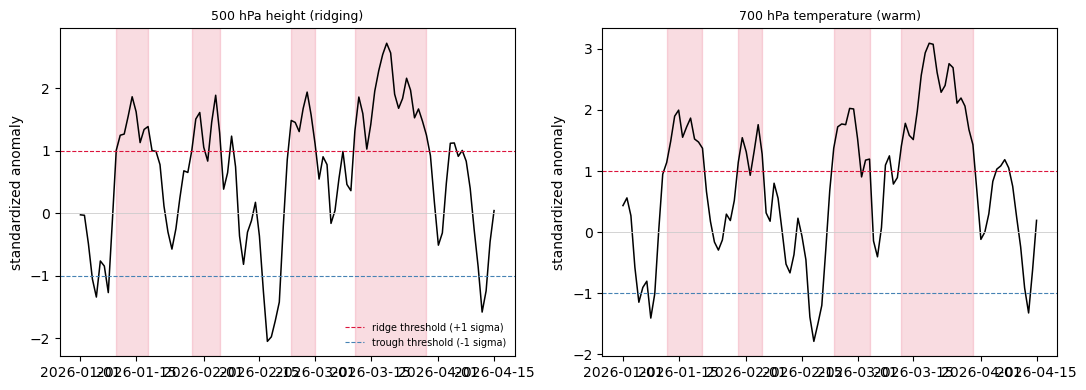

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (col, label) in zip(axes, VARS):
    window = sanom_series[label].loc['2026-01-01':'2026-04-15']
    ax.plot(window.index, window.values, color='k', lw=1.1)
    ax.axhline(1, color='crimson', lw=0.8, ls='--', label='ridge threshold (+1 sigma)')
    ax.axhline(-1, color='steelblue', lw=0.8, ls='--', label='trough threshold (-1 sigma)')
    ax.axhline(0, color='0.8', lw=0.6)
    for r in episodes_2026[label].itertuples():
        ax.axvspan(pd.Timestamp(r.start_date), pd.Timestamp(r.end_date), color='crimson', alpha=0.15)
    ax.set_title(label, fontsize=9)
    ax.set_ylabel('standardized anomaly')
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


## 7. Conclusion

**The first mechanism in this entire thread where March's own case supports, rather
than contradicts, the pattern -- though the statistical support behind it is
suggestive, not strong.**

- **Event-level: a real, nominally significant signal for Z500, in the hypothesized
  direction.** Gap minimum anomaly vs. the *following* episode's duration: rho=0.51
  (p=0.025, n=19) for Z500 -- a shallower preceding trough (less negative minimum)
  predicts a *longer* following episode, exactly as "insufficient trough passage"
  predicts. The fraction-below-threshold metric points the same direction (rho=-0.45,
  p=0.052, borderline). T700 is weaker and not significant (rho=0.34 p=0.156; rho=-0.23
  p=0.353). With 4 event-level tests, a Bonferroni bar would sit at p<0.0125 -- Z500's
  gap_min_sanom result (p=0.025) does not quite clear it, so this is suggestive at
  n=19, not confirmed.
- **Season-level: consistent direction for Z500, but not significant, and T700 isn't
  even consistent.** Season's weakest trough vs. total season episode-days: Z500
  rho=0.31 (p=0.24, n=16); T700 rho=0.13 (p=0.60, n=18). The fraction-based metric adds
  a genuine inconsistency: Z500 rho=-0.41 (p=0.12, hypothesis-consistent direction) but
  T700 rho=+0.21 (p=0.41, wrong direction) -- not a clean cross-variable confirmation.
- **WY2026's own three gaps are a strikingly clean illustration of the hypothesis, even
  though the population-level support is only suggestive.** All three Z500 gaps were
  shallow relative to history (84th, 32nd, and 95th percentile on "how shallow," i.e.
  weaker-than-typical troughs for two of three, with the Feb gap the one real
  exception). Two of the three never reached -1 sigma at all (frac_below_-1 = 0.00,
  16th percentile -- unusually weak). **Most notably: the gap immediately preceding
  March (Mar 2-10) was the *shallowest of WY2026's own three gaps* (min_sanom=-0.16,
  95th percentile -- barely dipped negative at all) and is immediately followed by the
  19-day record episode.** This is the first mechanism tested in this entire
  investigation where March's specific case aligns with, rather than defies, the
  direction of the (modest) relationship found in the historical record -- every prior
  mechanism (jet speed, WAF convergence/pulses, antecedent snowpack, QRA amplitude/
  phase/waveguide) had March sitting as an outlier *against* its own population
  relationship. Here it's a confirming case, not a contradicting one.
- **Caveat this needs, stated plainly:** n=19 event-level gaps (and n=16-18 at the
  season level) is a small sample for a Spearman test, the result does not survive a
  strict multiple-comparisons correction, and T700 does not confirm Z500 cleanly at
  either level. This is meaningfully different in character from this notebook's
  predecessors (contradicted or wrong-signed) but should be read as "the most
  promising lead so far, worth a larger/more careful follow-up," not as a settled
  explanation.

**Net effect on the open mechanism question.** Of roughly a dozen hypotheses tested
across ten notebooks, this is the first to (a) show a result in the hypothesized
direction with nominal significance at the event level, and (b) have March's own case
exemplify rather than contradict it -- specifically, the weak trough right before
March's onset. It does not clear the bar this project has used elsewhere (Bonferroni
correction, cross-variable confirmation) to call a result settled, and the season-level
test and T700 side are not confirmatory. But as a lead for further investigation --
larger samples, a formal trough-detection algorithm rather than a continuous proxy, or
testing whether the *composition* of a season's gaps (not just the worst one) matters
-- this is the strongest candidate this mechanism thread has produced.
